### KNN classifier: heart dataset


import libs and load data


In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [8]:
df = pd.read_csv("Heart_dataset")
X=df.drop(columns="HeartDisease")
y=df["HeartDisease"]
display(df.head())


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### train test split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### Prepare the features and train KNN

In [10]:
heart_categorical = X.select_dtypes(
    include=["object", "category", "string"]
).columns

heart_numeric = X.select_dtypes(include=["number"]).columns

heart_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), heart_numeric),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), heart_categorical)
    ]
)

knn_classifier = Pipeline(steps=[
    ("preprocessor", heart_preprocessor),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])

knn_classifier.fit(X_train, y_train);

n_neighbors=5 means that for each new example, KNN looks at the five closest training examples and predicts the majority class.

### Predict and evaluate

Accuracy: 0.897

Confusion matrix:
[[73  9]
 [10 92]]

Classification report:
                  precision    recall  f1-score   support

No heart disease       0.88      0.89      0.88        82
   Heart disease       0.91      0.90      0.91       102

        accuracy                           0.90       184
       macro avg       0.90      0.90      0.90       184
    weighted avg       0.90      0.90      0.90       184



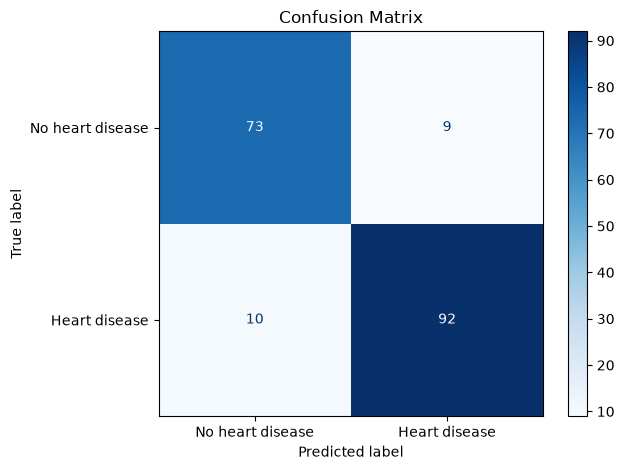

In [12]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

heart_predictions = knn_classifier.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, heart_predictions), 3))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, heart_predictions))

print("\nClassification report:")
print(classification_report(
    y_test,
    heart_predictions,
    target_names=["No heart disease", "Heart disease"]
))

ConfusionMatrixDisplay(
        confusion_matrix= confusion_matrix(y_test, heart_predictions),
        display_labels=["No heart disease", "Heart disease"],
    ).plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix")
plt.tight_layout()
plt.show()
